# Metacatalog classifications

Aggregate unique cross-match associations from
`metacatalog_associations.parquet` (written by radio / optical / x-ray
crossmatch notebooks). Harmonize native labels into a coarse taxonomy, flag
per-`meta_id` conflicts, and visualize the mix.

**Does not re-run crossmatches.** Re-run the individual notebooks to refresh
association rows (replace-by-`catalog`).

| Harmonized | Typical sources |
| --- | --- |
| `star` | Freund2022; MilliQuas `S`; eRASS negative `class_gal_exgal` |
| `galaxy` | NEDLVS; eRASS positive codes |
| `agn` | MilliQuas `Q`/`A`/`B`/`K`/`N`; eRASS blazar |
| `cluster` | Xu2022 |
| `xray` | 2RXS; eRASS without class |
| `radio` | VLSSR / NVSS / VLASS / LoDeSS |
| `unknown` | unrecognized native label |

**Conflict:** a `meta_id` with ≥2 distinct harmonized labels keeps all evidence
rows; the summary marks `conflict=True`.

**Class samples / SEDs:** `meta_ids_for_classes` selects `meta_id`s by
harmonized (or native) label; `plot_spectra_for_meta_ids` draws Total-flux SEDs
from `metacatalog_spectral.parquet` (preferred) or the fusion metacatalog.

**Run cells in order.** Reload from disk / restart the kernel after API changes.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lwa_catalog import CatalogLayout, read_metacatalog
from lwa_catalog.analyze import (
    flag_association_conflicts,
    gather_band_flux_measurements,
    harmonize_associations,
    meta_ids_for_classes,
    meta_ids_for_class_and_spectral,
    read_associations,
    resolve_sed_bands,
    summarize_classifications,
    summarize_classifications_text,
)
from lwa_catalog.analyze.spectral import SingleSpectrumFit, evaluate_taylor_spectrum
from lwa_catalog.constants import SUBBAND_BANDS_MHZ, SUBBAND_REF_FREQ_MHZ

# --- operator config ---
CATALOG_DIR = Path("/fast/claw/metacatalog_healpix_IdTR-0.75s_subband2")
# Optional subset of catalog ids, e.g. ("eRASS3", "MilliQuas", "Freund2022").
# None keeps every catalog present in the associations table.
CATALOG_FILTER: tuple[str, ...] | None = None
# How many conflicting meta_ids to show in the sample table.
CONFLICT_SAMPLE_N = 40
# Class-sample / SED defaults (override in the Class samples cell).
CLASS_SAMPLE_LABELS: tuple[str, ...] = ("star",)
CLASS_SAMPLE_N = 12
CLASS_SAMPLE_EXCLUSIVE = True
CLASS_SAMPLE_EXCLUDE_CONFLICTS = True
# "gallery" = one subplot per source; "overlay" = all on one axes.
CLASS_SAMPLE_LAYOUT: str = "overlay"
# Divide each SED by S(ν_ref); None leaves absolute Jy. Typical: SUBBAND_REF_FREQ_MHZ.
CLASS_SAMPLE_NORMALIZE_MHZ: float | None = 78

layout = CatalogLayout(CATALOG_DIR)
ASSOCIATIONS_PATH = layout.metacatalog_associations()

print("CATALOG_DIR =", layout.root.resolve())
print("ASSOCIATIONS_PATH =", ASSOCIATIONS_PATH.resolve())
print(
    "associations exists:" if ASSOCIATIONS_PATH.is_file() else "associations MISSING:",
    ASSOCIATIONS_PATH.resolve(),
)
print("CATALOG_FILTER =", CATALOG_FILTER)
print(
    "spectral exists:" if layout.metacatalog_spectral().is_file() else "spectral MISSING:",
    layout.metacatalog_spectral().resolve(),
)


CATALOG_DIR = /fast/claw/metacatalog_healpix_IdTR-0.75s_subband2
ASSOCIATIONS_PATH = /fast/claw/metacatalog_healpix_IdTR-0.75s_subband2/metacatalog_associations.parquet
associations exists: /fast/claw/metacatalog_healpix_IdTR-0.75s_subband2/metacatalog_associations.parquet
CATALOG_FILTER = None
spectral exists: /fast/claw/metacatalog_healpix_IdTR-0.75s_subband2/metacatalog_spectral.parquet


## Load associations

Reads the shared long-form table. Optionally filters to `CATALOG_FILTER`.
Adds `class_harmonized` for downstream tables / plots.


In [2]:
assoc_raw = read_associations(layout)
if assoc_raw.empty:
    raise FileNotFoundError(
        f"No associations rows at {ASSOCIATIONS_PATH.resolve()}. "
        "Run crossmatch notebooks with WRITE_ASSOCIATIONS / WRITE_CROSSMATCH first."
    )

if CATALOG_FILTER is not None:
    wanted = {str(c) for c in CATALOG_FILTER}
    assoc = assoc_raw.loc[assoc_raw["catalog"].astype(str).isin(wanted)].copy()
else:
    assoc = assoc_raw.copy()

if assoc.empty:
    raise ValueError(f"No rows left after CATALOG_FILTER={CATALOG_FILTER}")

assoc = harmonize_associations(assoc)
conflicts = flag_association_conflicts(assoc)
print(summarize_classifications_text(assoc))
print(f"\nrows after filter: {len(assoc):,}  catalogs={sorted(assoc['catalog'].astype(str).unique())}")


Associations:                  27895
Unique meta_id:                20714
Catalogs:                          4
Conflict meta_ids:                 0
Harmonized:
  radio         27895

rows after filter: 27,895  catalogs=['LoDeSS', 'NVSS', 'VLASS', 'VLSSR']


## Native class counts by catalog


In [3]:
native_counts = (
    assoc.groupby(["catalog", "class_native"], dropna=False)
    .size()
    .rename("n")
    .reset_index()
    .sort_values(["catalog", "n"], ascending=[True, False])
)
display(native_counts)

harmonized_counts = (
    assoc["class_harmonized"]
    .astype(str)
    .value_counts(dropna=False)
    .rename("n")
    .to_frame()
)
display(harmonized_counts)


,catalog,class_native,n
0,LoDeSS,LoDeSS,3064
1,NVSS,NVSS,7321
2,VLASS,VLASS,4088
3,VLSSR,VLSSR,13422


,n
class_harmonized,
radio,27895


## Conflict sample

`meta_id`s with ≥2 distinct harmonized labels. All association evidence rows for
those ids are listed (capped by `CONFLICT_SAMPLE_N` meta ids).


In [4]:
conflict_ids = conflicts.loc[conflicts["conflict"], "meta_id"]
print(f"conflict meta_ids: {len(conflict_ids):,} / {len(conflicts):,}")
display(conflicts.loc[conflicts["conflict"]].head(CONFLICT_SAMPLE_N))

if len(conflict_ids):
    sample_ids = set(conflict_ids.head(CONFLICT_SAMPLE_N).tolist())
    conflict_rows = assoc.loc[assoc["meta_id"].isin(sample_ids)].sort_values(
        ["meta_id", "catalog"]
    )
    display(
        conflict_rows[
            [
                c
                for c in (
                    "meta_id",
                    "catalog",
                    "ref_id",
                    "class_native",
                    "class_harmonized",
                    "sep_arcsec",
                )
                if c in conflict_rows.columns
            ]
        ]
    )
else:
    print("No conflicts under the current filter.")


conflict meta_ids: 0 / 20,714


,meta_id,n_associations,n_harmonized,harmonized_labels,conflict


No conflicts under the current filter.


## Harmonized class pie


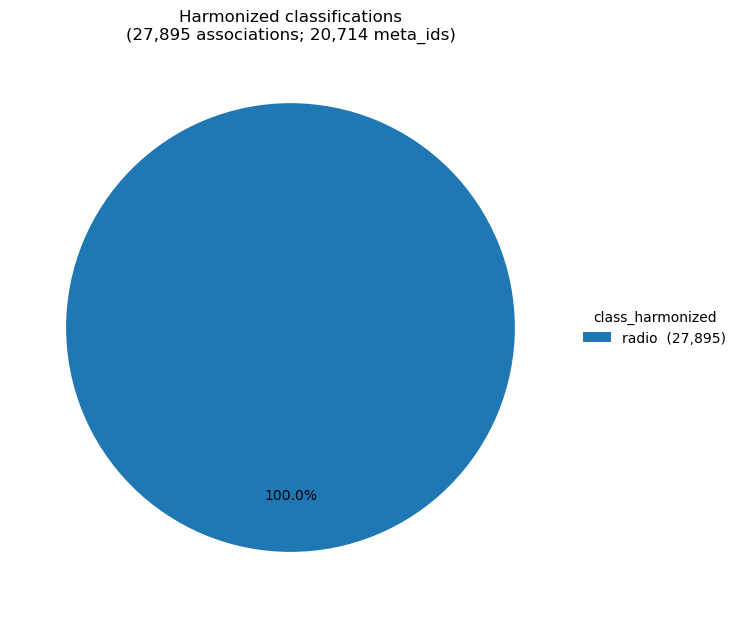

In [5]:
%matplotlib inline

counts = assoc["class_harmonized"].astype(str).value_counts(dropna=False)
if counts.empty:
    print("Nothing to plot.")
else:
    fig, ax = plt.subplots(figsize=(7.5, 7.5))
    wedges, _texts, _autotexts = ax.pie(
        counts.to_numpy(dtype=float),
        labels=None,
        autopct=lambda p: f"{p:.1f}%" if p >= 2.0 else "",
        startangle=90,
        pctdistance=0.75,
    )
    ax.legend(
        wedges,
        [f"{lab}  ({int(n):,})" for lab, n in counts.items()],
        title="class_harmonized",
        loc="center left",
        bbox_to_anchor=(1.0, 0.5),
        frameon=False,
    )
    ax.set_title(
        f"Harmonized classifications\n"
        f"({len(assoc):,} associations; {assoc['meta_id'].nunique():,} meta_ids)"
    )
    plt.tight_layout()
    plt.show()


## Catalog × harmonized stacked bar


class_harmonized,radio
catalog,
LoDeSS,3064
NVSS,7321
VLASS,4088
VLSSR,13422


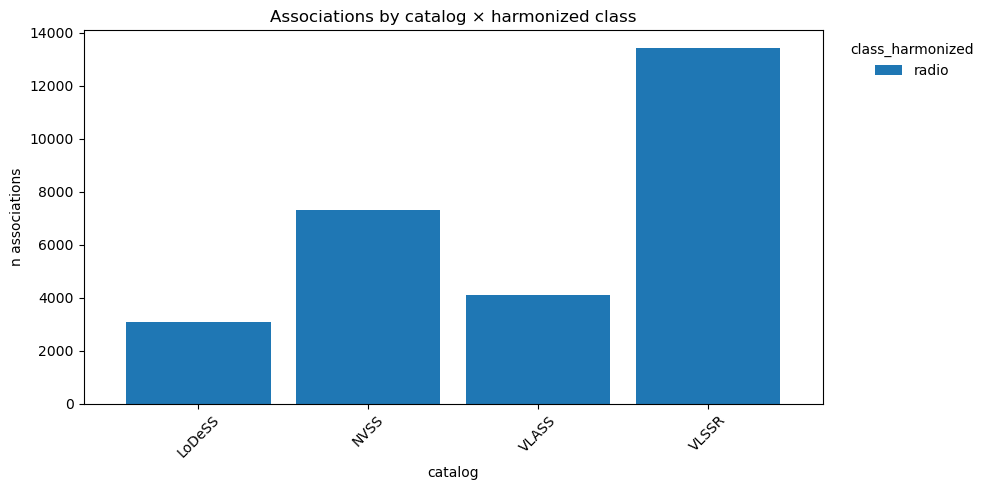

In [6]:
cross = (
    assoc.groupby(["catalog", "class_harmonized"], dropna=False)
    .size()
    .unstack(fill_value=0)
    .sort_index()
)
display(cross)

if cross.empty:
    print("Nothing to plot.")
else:
    fig, ax = plt.subplots(figsize=(10, 5))
    cross.plot(kind="bar", stacked=True, ax=ax, width=0.85)
    ax.set_xlabel("catalog")
    ax.set_ylabel("n associations")
    ax.set_title("Associations by catalog × harmonized class")
    ax.legend(title="class_harmonized", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()


## Conflict-only subset (optional)

Same stacked bar restricted to associations whose `meta_id` is in conflict.


In [7]:
conflict_id_set = set(conflicts.loc[conflicts["conflict"], "meta_id"].tolist())
conflict_assoc = assoc.loc[assoc["meta_id"].isin(conflict_id_set)].copy()
print(f"conflict associations: {len(conflict_assoc):,}")

if conflict_assoc.empty:
    print("No conflict associations to plot.")
else:
    cross_c = (
        conflict_assoc.groupby(["catalog", "class_harmonized"], dropna=False)
        .size()
        .unstack(fill_value=0)
        .sort_index()
    )
    display(cross_c)
    fig, ax = plt.subplots(figsize=(10, 5))
    cross_c.plot(kind="bar", stacked=True, ax=ax, width=0.85)
    ax.set_xlabel("catalog")
    ax.set_ylabel("n associations")
    ax.set_title("Conflict meta_ids only — catalog × harmonized class")
    ax.legend(title="class_harmonized", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()


conflict associations: 0
No conflict associations to plot.


## Class samples and spectra

`meta_ids_for_classes` returns unique `meta_id`s whose associations match one or
more labels (`class_harmonized` by default). Use `exclusive=True` to require that
all of a source's labels fall in the requested set, and `exclude_conflicts=True`
to drop multi-label `meta_id`s.

`plot_spectra_for_meta_ids` draws Total-flux SEDs from the spectral metacatalog
when present (else fusion). Layout modes:

| `layout` | Behavior |
| --- | --- |
| `"gallery"` | One subplot per `meta_id` |
| `"overlay"` | All SEDs on one axes |

Set `normalize_mhz` (e.g. `55`) to plot `S(ν)/S(ν_ref)` so shapes stack for
comparison; `None` keeps absolute Jy. Normalization uses the Taylor model when
present, else log–log interpolation of unconfused points. Confused channels
(`n_confused != 1`) use `x` markers.

In [8]:
def _row_to_spectrum_fit(row: pd.Series, *, prefix: str = "spec_") -> SingleSpectrumFit | None:
    """Build a SingleSpectrumFit from stored ``{prefix}model_*`` columns."""
    n_terms_col = f"{prefix}model_n_terms"
    if n_terms_col not in row.index or pd.isna(row.get(n_terms_col)):
        return None
    n_terms = int(row[n_terms_col])
    if n_terms < 2:
        return None
    return SingleSpectrumFit(
        n_terms=n_terms,
        bic=float(row.get(f"{prefix}model_bic", float("nan"))),
        chi2_red=float(row.get(f"{prefix}model_chi2_red", float("nan"))),
        n_flux=int(row.get(f"{prefix}model_n_flux", 0)),
        coeffs=(
            float(row.get(f"{prefix}model_a0", float("nan"))),
            float(row.get(f"{prefix}model_a1", float("nan"))),
            float(row.get(f"{prefix}model_a2", float("nan"))),
            float(row.get(f"{prefix}model_a3", float("nan"))),
        ),
        nu0_mhz=float(row.get(f"{prefix}model_nu0_mhz", SUBBAND_REF_FREQ_MHZ)),
    )


def _flux_at_ref_mhz(
    nu_mhz: np.ndarray,
    flux_jy: np.ndarray,
    *,
    ref_mhz: float,
    fit: SingleSpectrumFit | None,
) -> float:
    """Positive finite S(ν_ref) from Taylor fit or log–log interpolation."""
    ref = float(ref_mhz)
    if fit is not None:
        s = float(evaluate_taylor_spectrum(np.array([ref * 1e6]), fit)[0])
        if np.isfinite(s) and s > 0:
            return s
    ok = np.isfinite(nu_mhz) & np.isfinite(flux_jy) & (flux_jy > 0) & (nu_mhz > 0)
    if ok.sum() == 0:
        return float("nan")
    x = nu_mhz[ok]
    y = flux_jy[ok]
    order = np.argsort(x)
    x, y = x[order], y[order]
    if x.size == 1:
        return float(y[0]) if np.isclose(x[0], ref, rtol=0.05) else float("nan")
    if ref < x[0] or ref > x[-1]:
        # Nearest in-band point if ref is outside the measured span.
        return float(y[np.argmin(np.abs(x - ref))])
    return float(np.exp(np.interp(np.log(ref), np.log(x), np.log(y))))


def _spectrum_arrays(
    row: pd.Series,
    *,
    flux_kind: str = "total",
    normalize_mhz: float | None = None,
):
    """Return plotted arrays and metadata for one catalog row.

    Returns
    -------
    dict or None
        Keys: label, nu_mhz, flux, err, is_lwa, is_fit, fit, scale.
        ``scale`` is S(ν_ref) when normalizing, else 1.0. None if unusable.
    """
    meta_id = row.get("meta_id")
    label = f"meta_id={int(meta_id)}" if pd.notna(meta_id) else "source"

    sed_bands = resolve_sed_bands(row, flux_kind=flux_kind)
    nu_hz, flux_jy, err_jy, point_bands = gather_band_flux_measurements(
        row, bands=sed_bands, flux_kind=flux_kind
    )
    if nu_hz.size == 0:
        return None

    _, _, _, fit_bands = gather_band_flux_measurements(
        row, bands=sed_bands, flux_kind=flux_kind, unconfused_only=True
    )
    fit_band_set = set(fit_bands)
    nu_mhz = nu_hz / 1e6
    lwa_set = set(SUBBAND_BANDS_MHZ)
    is_lwa = np.array([b in lwa_set for b in point_bands], dtype=bool)
    is_fit = np.array([b in fit_band_set for b in point_bands], dtype=bool)
    fit = _row_to_spectrum_fit(row)

    scale = 1.0
    if normalize_mhz is not None:
        # Prefer unconfused points for the reference scale.
        ref_flux = flux_jy.copy()
        ref_nu = nu_mhz.copy()
        if is_fit.any():
            ref_flux = flux_jy[is_fit]
            ref_nu = nu_mhz[is_fit]
        scale = _flux_at_ref_mhz(ref_nu, ref_flux, ref_mhz=float(normalize_mhz), fit=fit)
        if not (np.isfinite(scale) and scale > 0):
            return None

    return {
        "label": label,
        "meta_id": int(meta_id) if pd.notna(meta_id) else None,
        "nu_mhz": nu_mhz,
        "flux": flux_jy / scale,
        "err": err_jy / scale,
        "is_lwa": is_lwa,
        "is_fit": is_fit,
        "fit": fit,
        "scale": float(scale),
    }


def _draw_spectrum(
    ax,
    spec: dict,
    *,
    color=None,
    normalize_mhz: float | None = None,
    show_label: bool = False,
    alpha: float = 0.9,
) -> None:
    """Draw one prepared spectrum dict onto *ax*."""
    nu_mhz = spec["nu_mhz"]
    flux = spec["flux"]
    err = spec["err"]
    is_lwa = spec["is_lwa"]
    is_fit = spec["is_fit"]
    label = spec["label"] if show_label else None

    legend_used = False

    def _errorbar(mask: np.ndarray, *, fmt: str, markersize: float) -> None:
        nonlocal legend_used
        if not mask.any():
            return
        lbl = None
        if show_label and not legend_used:
            lbl = label
            legend_used = True
        ax.errorbar(
            nu_mhz[mask],
            flux[mask],
            yerr=err[mask],
            fmt=fmt,
            capsize=2,
            markersize=markersize,
            markeredgewidth=1.6 if fmt == "x" else 1.0,
            color=color,
            alpha=alpha,
            label=lbl,
        )

    _errorbar(is_lwa & is_fit, fmt="o", markersize=5)
    _errorbar(is_lwa & ~is_fit, fmt="x", markersize=6)
    _errorbar((~is_lwa) & is_fit, fmt="s", markersize=4)
    _errorbar((~is_lwa) & ~is_fit, fmt="x", markersize=6)

    fit = spec["fit"]
    if fit is not None:
        nu_curve = np.geomspace(float(nu_mhz.min()), float(nu_mhz.max()), 80)
        y_curve = evaluate_taylor_spectrum(nu_curve * 1e6, fit)
        if normalize_mhz is not None:
            y_curve = y_curve / spec["scale"]
        ax.plot(nu_curve, y_curve, "-", lw=1.2, color=color, alpha=alpha)


def _flux_ylabel(flux_kind: str, normalize_mhz: float | None) -> str:
    if normalize_mhz is not None:
        return rf"$S(\nu)/S({normalize_mhz:g}\,\mathrm{{MHz}})$"
    if flux_kind == "total":
        return "Total flux (Jy)"
    return "Peak flux (Jy/beam)"


def plot_spectra_for_meta_ids(
    meta_ids,
    metacatalog: pd.DataFrame,
    *,
    max_n: int = 12,
    ncols: int = 3,
    flux_kind: str = "total",
    layout: str = "gallery",
    normalize_mhz: float | None = None,
    figsize_per: tuple[float, float] = (3.6, 2.8),
    figsize_overlay: tuple[float, float] = (8.0, 5.0),
):
    """Plot SEDs for a list of ``meta_id``s.

    Parameters
    ----------
    layout
        ``"gallery"`` — one subplot per source; ``"overlay"`` — all on one axes.
    normalize_mhz
        If set, divide each SED by ``S(ν_ref)`` (Taylor when available, else
        log–log interpolation of unconfused points). Sources without a usable
        scale are skipped.

    Missing ids are skipped (printed). Returns ``(fig, used_ids)``.
    """
    if "meta_id" not in metacatalog.columns:
        raise ValueError("metacatalog missing meta_id column")
    layout = str(layout).strip().lower()
    if layout not in {"gallery", "overlay"}:
        raise ValueError(f"layout must be 'gallery' or 'overlay', got {layout!r}")

    wanted = [int(x) for x in list(meta_ids)[: int(max_n)]]
    by_id = metacatalog.drop_duplicates(subset=["meta_id"]).set_index("meta_id", drop=False)
    rows: list[pd.Series] = []
    missing: list[int] = []
    for mid in wanted:
        if mid in by_id.index:
            hit = by_id.loc[mid]
            rows.append(hit.iloc[0] if isinstance(hit, pd.DataFrame) else hit)
        else:
            missing.append(mid)
    if missing:
        print(
            f"meta_ids not in metacatalog ({len(missing)}): "
            f"{missing[:20]}{'…' if len(missing) > 20 else ''}"
        )

    specs: list[dict] = []
    skipped_norm: list[int] = []
    for row in rows:
        spec = _spectrum_arrays(row, flux_kind=flux_kind, normalize_mhz=normalize_mhz)
        if spec is None:
            mid = int(row["meta_id"]) if pd.notna(row.get("meta_id")) else -1
            if normalize_mhz is not None:
                skipped_norm.append(mid)
            continue
        specs.append(spec)
    if skipped_norm:
        print(
            f"skipped (no S at {normalize_mhz:g} MHz): "
            f"{skipped_norm[:20]}{'…' if len(skipped_norm) > 20 else ''}"
        )
    if not specs:
        print("No matching rows to plot.")
        return None, []

    used_ids = [s["meta_id"] for s in specs if s["meta_id"] is not None]
    norm_note = (
        f", normalized @ {normalize_mhz:g} MHz" if normalize_mhz is not None else ""
    )
    ylabel = _flux_ylabel(flux_kind, normalize_mhz)

    if layout == "overlay":
        fig, ax = plt.subplots(figsize=figsize_overlay)
        cmap = plt.cm.viridis
        colors = cmap(np.linspace(0.15, 0.85, len(specs)))
        for spec, color in zip(specs, colors, strict=True):
            _draw_spectrum(
                ax,
                spec,
                color=color,
                normalize_mhz=normalize_mhz,
                show_label=len(specs) <= 20,
                alpha=0.85,
            )
        if normalize_mhz is not None:
            ax.axvline(float(normalize_mhz), color="0.5", ls=":", lw=1)
            ax.axhline(1.0, color="0.5", ls=":", lw=1)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.grid(True, which="both", alpha=0.3)
        ax.set_xlabel("Frequency (MHz)")
        ax.set_ylabel(ylabel)
        ax.set_title(f"SEDs for {len(specs)} meta_id(s){norm_note}")
        if len(specs) <= 20:
            ax.legend(fontsize=8, loc="best", frameon=False)
        fig.tight_layout()
        return fig, used_ids

    n = len(specs)
    ncols = max(1, int(ncols))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(figsize_per[0] * ncols, figsize_per[1] * nrows),
        squeeze=False,
    )
    for i, spec in enumerate(specs):
        r, c = divmod(i, ncols)
        ax = axes[r][c]
        _draw_spectrum(ax, spec, normalize_mhz=normalize_mhz, show_label=False)
        if normalize_mhz is not None:
            ax.axvline(float(normalize_mhz), color="0.5", ls=":", lw=1)
            ax.axhline(1.0, color="0.5", ls=":", lw=1)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.grid(True, which="both", alpha=0.3)
        ax.set_title(spec["label"], fontsize=9)
    for j in range(n, nrows * ncols):
        r, c = divmod(j, ncols)
        axes[r][c].set_axis_off()

    for ax in axes[-1, :]:
        ax.set_xlabel("Frequency (MHz)")
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    fig.suptitle(f"SEDs for {len(specs)} meta_id(s){norm_note}", y=1.01)
    fig.tight_layout()
    return fig, used_ids


# Prefer spectral product (survey fluxes + optional Taylor columns).
meta = read_metacatalog(layout, prefer_spectral=True, quality_mask=None, validate=False)
print(
    f"metacatalog rows: {len(meta):,}  columns with Total_flux_*: "
    f"{sum(c.startswith('Total_flux_') for c in meta.columns)}"
)
print(f"has spec_model_*: {any(c.startswith('spec_model_') for c in meta.columns)}")

sample_ids = meta_ids_for_classes(
    assoc,
    CLASS_SAMPLE_LABELS,
    exclusive=CLASS_SAMPLE_EXCLUSIVE,
    exclude_conflicts=CLASS_SAMPLE_EXCLUDE_CONFLICTS,
)
print(
    f"class={CLASS_SAMPLE_LABELS!r} exclusive={CLASS_SAMPLE_EXCLUSIVE} "
    f"exclude_conflicts={CLASS_SAMPLE_EXCLUDE_CONFLICTS} → {len(sample_ids):,} meta_ids"
)
display(pd.DataFrame({"meta_id": sample_ids}).head(CLASS_SAMPLE_N))

metacatalog rows: 160,117  columns with Total_flux_*: 19
has spec_model_*: True
class=('star',) exclusive=True exclude_conflicts=True → 0 meta_ids


,meta_id


In [12]:
class_name = 'radio'
sample_ids = meta_ids_for_classes(
    assoc,
    class_name,
    exclusive=CLASS_SAMPLE_EXCLUSIVE,
    exclude_conflicts=CLASS_SAMPLE_EXCLUDE_CONFLICTS,
)
print(f'{len(sample_ids)} sources named {class_name}')

20714 sources named radio


/opt/devel/claw/envs/py312/lib/python3.12/site-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


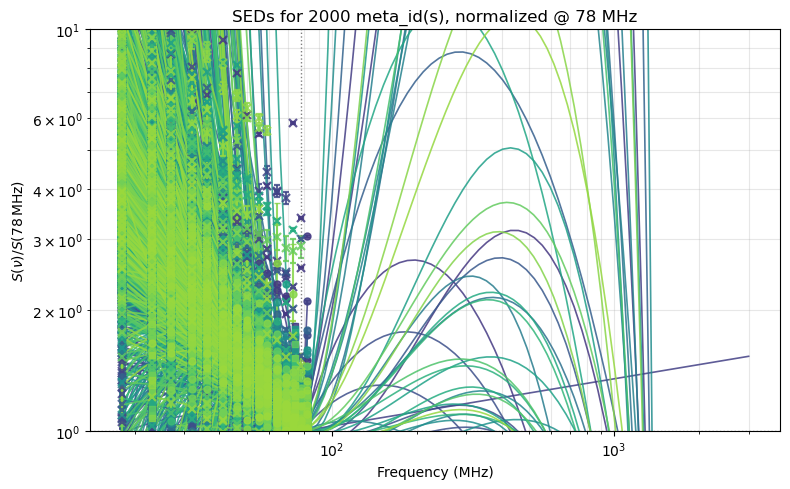

In [13]:
%matplotlib inline
fig, used = plot_spectra_for_meta_ids(
    sample_ids,
    meta,
    max_n=2000,
    layout='overlay',
    normalize_mhz=CLASS_SAMPLE_NORMALIZE_MHZ,
)
if fig is not None:
    plt.show()


## Spectral fit coefficient summary

Given a set of `meta_id`s (defaults to `sample_ids` from above), summarize the
stored Taylor coefficients on the spectral metacatalog:

1. **n_terms=2** — histogram of `spec_model_a1` (spectral index at ν₀) with mean
   and median marks.
2. **n_terms=3** — scatter of `spec_model_a1` vs `spec_model_a2` with mean and
   median marks on each axis.
3. **n_terms=4** — two `a1`–`a2` scatters split by the sign of `spec_model_a3`
   (`a3 > 0` and `a3 < 0`).

Text stats for each panel are printed below the figure.


Spectral fit summary for 20,714 requested meta_ids (20,714 rows found in metacatalog)
n_terms value_counts:
spec_model_n_terms
2.0    13389
3.0     4174
4.0     2948
NaN      203
n_terms=2 a1: n=13,389  mean=-1.004  median=-0.9656  std=1.023  min=-23.15  max=22.97
n_terms=3 a1–a2: n=4,174
  a1  mean=-0.9727  median=-0.8616  std=4.192
  a2  mean=0.1895  median=-0.09989  std=6.773
  corr(a1,a2)=-0.95
n_terms=4, a3 > 0 a1–a2: n=1,336
  a1  mean=4.401  median=-0.3376  std=14.63
  a2  mean=-22  median=-3.988  std=54.51
  corr(a1,a2)=-0.9507
  a3  mean=28.43  median=5.221  std=69.24
n_terms=4, a3 < 0 a1–a2: n=1,612
  a1  mean=-6.705  median=-1.518  std=16
  a2  mean=20.32  median=3.615  std=50.97
  corr(a1,a2)=-0.9516
  a3  mean=-22.02  median=-3.572  std=57.69


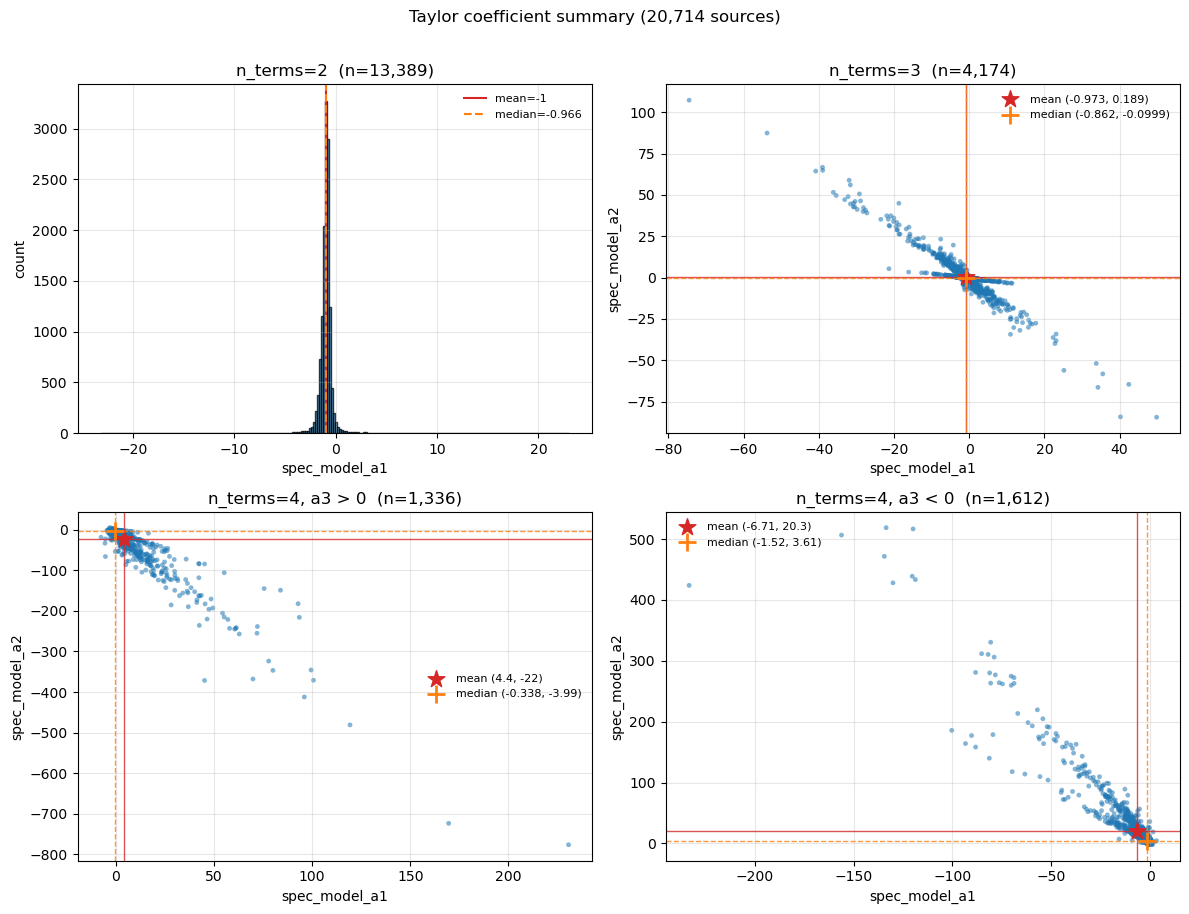

In [14]:
def _finite_series(*cols: pd.Series) -> pd.DataFrame:
    """Stack *cols* and keep rows where every column is finite."""
    frame = pd.concat([c.rename(c.name or f"c{i}") for i, c in enumerate(cols)], axis=1)
    mask = np.ones(len(frame), dtype=bool)
    for c in frame.columns:
        v = pd.to_numeric(frame[c], errors="coerce")
        frame[c] = v
        mask &= np.isfinite(v.to_numpy())
    return frame.loc[mask].copy()


def _mark_1d(ax, values: np.ndarray, *, orientation: str = "v") -> tuple[float, float]:
    """Draw mean (solid) and median (dashed) lines; return (mean, median)."""
    mean = float(np.mean(values))
    median = float(np.median(values))
    if orientation == "v":
        ax.axvline(mean, color="C3", ls="-", lw=1.5, label=f"mean={mean:.3g}")
        ax.axvline(median, color="C1", ls="--", lw=1.5, label=f"median={median:.3g}")
    else:
        ax.axhline(mean, color="C3", ls="-", lw=1.5, label=f"mean={mean:.3g}")
        ax.axhline(median, color="C1", ls="--", lw=1.5, label=f"median={median:.3g}")
    return mean, median


def _mark_2d(ax, x: np.ndarray, y: np.ndarray) -> dict[str, float]:
    """Mark mean (star) and median (+) of *x*, *y*; return summary stats."""
    stats = {
        "x_mean": float(np.mean(x)),
        "x_median": float(np.median(x)),
        "y_mean": float(np.mean(y)),
        "y_median": float(np.median(y)),
    }
    ax.axvline(stats["x_mean"], color="C3", ls="-", lw=1.0, alpha=0.8)
    ax.axvline(stats["x_median"], color="C1", ls="--", lw=1.0, alpha=0.8)
    ax.axhline(stats["y_mean"], color="C3", ls="-", lw=1.0, alpha=0.8)
    ax.axhline(stats["y_median"], color="C1", ls="--", lw=1.0, alpha=0.8)
    ax.scatter(
        [stats["x_mean"]],
        [stats["y_mean"]],
        marker="*",
        s=160,
        c="C3",
        zorder=5,
        label=f"mean ({stats['x_mean']:.3g}, {stats['y_mean']:.3g})",
    )
    ax.scatter(
        [stats["x_median"]],
        [stats["y_median"]],
        marker="+",
        s=160,
        c="C1",
        zorder=5,
        linewidths=2,
        label=f"median ({stats['x_median']:.3g}, {stats['y_median']:.3g})",
    )
    return stats


def _fmt_stats_1d(name: str, values: np.ndarray, mean: float, median: float) -> str:
    return (
        f"{name}: n={values.size:,}  "
        f"mean={mean:.4g}  median={median:.4g}  "
        f"std={float(np.std(values, ddof=1)) if values.size > 1 else float('nan'):.4g}  "
        f"min={float(np.min(values)):.4g}  max={float(np.max(values)):.4g}"
    )


def _fmt_stats_2d(name: str, x: np.ndarray, y: np.ndarray, stats: dict[str, float]) -> str:
    lines = [
        f"{name}: n={x.size:,}",
        f"  a1  mean={stats['x_mean']:.4g}  median={stats['x_median']:.4g}  "
        f"std={float(np.std(x, ddof=1)) if x.size > 1 else float('nan'):.4g}",
        f"  a2  mean={stats['y_mean']:.4g}  median={stats['y_median']:.4g}  "
        f"std={float(np.std(y, ddof=1)) if y.size > 1 else float('nan'):.4g}",
    ]
    if x.size > 1:
        corr = float(np.corrcoef(x, y)[0, 1])
        lines.append(f"  corr(a1,a2)={corr:.4g}")
    return "\n".join(lines)


def plot_spectral_fit_summary(
    meta_ids,
    metacatalog: pd.DataFrame,
    *,
    prefix: str = "spec_",
    figsize: tuple[float, float] = (12.0, 9.0),
):
    """Plot Taylor coefficient diagnostics for *meta_ids*.

    Layout
    ------
    - n_terms=2: histogram of ``a1`` with mean/median marks
    - n_terms=3: scatter ``a1`` vs ``a2`` with mean/median marks
    - n_terms=4: two ``a1``–``a2`` scatters for ``a3 > 0`` and ``a3 < 0``

    Prints a text summary of each panel. Returns ``(fig, summary_lines)``.
    """
    required = [
        "meta_id",
        f"{prefix}model_n_terms",
        f"{prefix}model_a1",
        f"{prefix}model_a2",
        f"{prefix}model_a3",
    ]
    missing_cols = [c for c in required if c not in metacatalog.columns]
    if missing_cols:
        raise ValueError(
            f"metacatalog missing spectral columns {missing_cols}; "
            "run metacatalog_spectral_modeling.ipynb / prefer_spectral load first"
        )

    wanted = {int(x) for x in meta_ids}
    sub = metacatalog.loc[metacatalog["meta_id"].isin(wanted)].copy()
    sub = sub.drop_duplicates(subset=["meta_id"], keep="first")
    n_terms = pd.to_numeric(sub[f"{prefix}model_n_terms"], errors="coerce")
    a1 = pd.to_numeric(sub[f"{prefix}model_a1"], errors="coerce")
    a2 = pd.to_numeric(sub[f"{prefix}model_a2"], errors="coerce")
    a3 = pd.to_numeric(sub[f"{prefix}model_a3"], errors="coerce")

    summary: list[str] = [
        f"Spectral fit summary for {len(wanted):,} requested meta_ids "
        f"({len(sub):,} rows found in metacatalog)",
        f"n_terms value_counts:\n{n_terms.value_counts(dropna=False).sort_index().to_string()}",
    ]

    fig, axes = plt.subplots(2, 2, figsize=figsize)

    # --- n_terms=2: a1 histogram ---
    ax = axes[0, 0]
    two = a1.loc[n_terms == 2]
    two = two[np.isfinite(two.to_numpy())]
    if two.empty:
        ax.text(0.5, 0.5, "no n_terms=2 sources", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        summary.append("n_terms=2 a1: n=0")
    else:
        vals = two.to_numpy(dtype=float)
        ax.hist(vals, bins="auto", color="C0", edgecolor="k", alpha=0.75)
        mean, median = _mark_1d(ax, vals, orientation="v")
        ax.set_xlabel(f"{prefix}model_a1")
        ax.set_ylabel("count")
        ax.set_title(f"n_terms=2  (n={vals.size:,})")
        ax.legend(fontsize=8, frameon=False)
        ax.grid(True, alpha=0.3)
        summary.append(_fmt_stats_1d("n_terms=2 a1", vals, mean, median))

    # --- n_terms=3: a1 vs a2 ---
    ax = axes[0, 1]
    three = _finite_series(a1.loc[n_terms == 3].rename("a1"), a2.loc[n_terms == 3].rename("a2"))
    if three.empty:
        ax.text(0.5, 0.5, "no n_terms=3 sources", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        summary.append("n_terms=3 a1–a2: n=0")
    else:
        x = three["a1"].to_numpy(dtype=float)
        y = three["a2"].to_numpy(dtype=float)
        ax.scatter(x, y, s=12, alpha=0.55, c="C0", edgecolors="none")
        stats = _mark_2d(ax, x, y)
        ax.set_xlabel(f"{prefix}model_a1")
        ax.set_ylabel(f"{prefix}model_a2")
        ax.set_title(f"n_terms=3  (n={x.size:,})")
        ax.legend(fontsize=8, frameon=False, loc="best")
        ax.grid(True, alpha=0.3)
        summary.append(_fmt_stats_2d("n_terms=3 a1–a2", x, y, stats))

    # --- n_terms=4: a1 vs a2 split by sign(a3) ---
    four_mask = n_terms == 4
    for ax, sign, title in (
        (axes[1, 0], 1, "n_terms=4, a3 > 0"),
        (axes[1, 1], -1, "n_terms=4, a3 < 0"),
    ):
        if sign > 0:
            sel = four_mask & (a3 > 0)
        else:
            sel = four_mask & (a3 < 0)
        panel = _finite_series(a1.loc[sel].rename("a1"), a2.loc[sel].rename("a2"), a3.loc[sel].rename("a3"))
        if panel.empty:
            ax.text(0.5, 0.5, f"no sources\n({title})", ha="center", va="center", transform=ax.transAxes)
            ax.set_axis_off()
            summary.append(f"{title}: n=0")
            continue
        x = panel["a1"].to_numpy(dtype=float)
        y = panel["a2"].to_numpy(dtype=float)
        a3_vals = panel["a3"].to_numpy(dtype=float)
        ax.scatter(x, y, s=12, alpha=0.55, c="C0", edgecolors="none")
        stats = _mark_2d(ax, x, y)
        ax.set_xlabel(f"{prefix}model_a1")
        ax.set_ylabel(f"{prefix}model_a2")
        ax.set_title(f"{title}  (n={x.size:,})")
        ax.legend(fontsize=8, frameon=False, loc="best")
        ax.grid(True, alpha=0.3)
        block = _fmt_stats_2d(title + " a1–a2", x, y, stats)
        a3_mean = float(np.mean(a3_vals))
        a3_med = float(np.median(a3_vals))
        block += (
            f"\n  a3  mean={a3_mean:.4g}  median={a3_med:.4g}  "
            f"std={float(np.std(a3_vals, ddof=1)) if a3_vals.size > 1 else float('nan'):.4g}"
        )
        summary.append(block)

    n4_zero = int(((n_terms == 4) & (a3 == 0)).sum())
    n4_nan = int(((n_terms == 4) & ~np.isfinite(a3.to_numpy())).sum())
    if n4_zero or n4_nan:
        summary.append(
            f"n_terms=4 excluded from sign split: a3==0 → {n4_zero:,}; "
            f"non-finite a3 → {n4_nan:,}"
        )

    fig.suptitle(f"Taylor coefficient summary ({len(sub):,} sources)", y=1.01)
    fig.tight_layout()

    print("\n".join(summary))
    return fig, summary


%matplotlib inline

# Uses sample_ids from the class-sample cells above (override here if needed).
fit_ids = sample_ids
fig_fit, _fit_summary = plot_spectral_fit_summary(fit_ids, meta)
if fig_fit is not None:
    plt.show()


## Galactic reddening vs spectral shape

Select sources by crossmatch class **and** Taylor-fit cuts
(`meta_ids_for_class_and_spectral`), query line-of-sight dust reddening with
[`dustmaps`](https://dustmaps.readthedocs.io/) SFD'98
(`E(B-V)` toward each `RA`/`DEC`), and scatter reddening against a spectral
coefficient (default `spec_model_a1`).

Requires `dustmaps` in the kernel env and SFD maps under `DUSTMAPS_DATA_DIR`
(default `/fast/claw/dustmaps`). Cite Green (2018) / Schlegel et al. (1998) if
you use these values.


In [ ]:
from astropy.coordinates import SkyCoord

from lwa_catalog.analyze import meta_ids_for_class_and_spectral

# --- reddening / selection config ---
DUSTMAPS_DATA_DIR = Path("/fast/claw/dustmaps")
# Class + spectral cuts (override freely).
REDDEN_CLASS: str | tuple[str, ...] = "radio"
REDDEN_EXCLUSIVE = True
REDDEN_EXCLUDE_CONFLICTS = True
REDDEN_N_TERMS: int | tuple[int, ...] | None = 2
REDDEN_A1: tuple[float | None, float | None] | None = None  # e.g. (-2.0, 0.5)
REDDEN_A2: tuple[float | None, float | None] | None = None
REDDEN_A3: tuple[float | None, float | None] | None = None
REDDEN_A3_SIGN: str | None = None  # ">" / "<" or None
REDDEN_MIN_N_FLUX: int | None = None
REDDEN_Y_COL = "spec_model_a1"
REDDEN_MAX_N: int | None = None  # cap for speed; None = all


def configure_dustmaps(data_dir: Path | str = DUSTMAPS_DATA_DIR) -> Path:
    """Point dustmaps at a local data tree (expects ``sfd/SFD_dust_4096_{ngp,sgp}.fits``)."""
    from dustmaps.config import config

    root = Path(data_dir)
    config["data_dir"] = str(root)
    sfd_dir = root / "sfd"
    for pole in ("ngp", "sgp"):
        path = sfd_dir / f"SFD_dust_4096_{pole}.fits"
        if not path.is_file():
            raise FileNotFoundError(
                f"Missing {path}. Download SFD maps into {sfd_dir} "
                "(e.g. from https://github.com/kbarbary/sfddata) or run "
                "`dustmaps.sfd.fetch()` when Dataverse is reachable."
            )
    return root


def ebv_for_meta_ids(
    meta_ids,
    metacatalog: pd.DataFrame,
    *,
    data_dir: Path | str = DUSTMAPS_DATA_DIR,
    extra_columns: tuple[str, ...] = (
        "spec_model_n_terms",
        "spec_model_a1",
        "spec_model_a2",
        "spec_model_a3",
        "spec_model_n_flux",
    ),
) -> pd.DataFrame:
    """Return one row per ``meta_id`` with SFD ``ebv`` (E(B-V)) at RA/DEC.

    Uses local :class:`dustmaps.sfd.SFDQuery`. Coordinates must be finite.
    """
    from dustmaps.sfd import SFDQuery

    configure_dustmaps(data_dir)
    if "meta_id" not in metacatalog.columns:
        raise ValueError("metacatalog missing meta_id")
    for col in ("RA", "DEC"):
        if col not in metacatalog.columns:
            raise ValueError(f"metacatalog missing {col}")

    wanted = [int(x) for x in meta_ids]
    sub = (
        metacatalog.loc[metacatalog["meta_id"].isin(wanted)]
        .drop_duplicates(subset=["meta_id"], keep="first")
        .copy()
    )
    if sub.empty:
        return pd.DataFrame(
            columns=["meta_id", "RA", "DEC", "ebv", *extra_columns]
        )

    ra = pd.to_numeric(sub["RA"], errors="coerce")
    dec = pd.to_numeric(sub["DEC"], errors="coerce")
    ok = np.isfinite(ra.to_numpy()) & np.isfinite(dec.to_numpy())
    sub = sub.loc[ok].copy()
    ra = ra.loc[ok]
    dec = dec.loc[ok]
    if sub.empty:
        raise ValueError("no rows with finite RA/DEC among requested meta_ids")

    coords = SkyCoord(ra.to_numpy(dtype=float), dec.to_numpy(dtype=float), unit="deg", frame="icrs")
    ebv = np.asarray(SFDQuery()(coords), dtype=float)

    out = pd.DataFrame(
        {
            "meta_id": sub["meta_id"].astype(np.int64).to_numpy(),
            "RA": ra.to_numpy(dtype=float),
            "DEC": dec.to_numpy(dtype=float),
            "ebv": ebv,
        }
    )
    for col in extra_columns:
        if col in sub.columns:
            out[col] = pd.to_numeric(sub[col], errors="coerce").to_numpy()
    return out.reset_index(drop=True)


def plot_ebv_vs_spectral(
    reddening: pd.DataFrame,
    *,
    y: str = "spec_model_a1",
    ax=None,
    s: float = 18,
    alpha: float = 0.65,
    figsize: tuple[float, float] = (7.5, 5.5),
):
    """Scatter SFD ``ebv`` vs a spectral column; mark mean/median of each axis.

    Returns ``(fig, ax, stats)``. Prints a short text summary.
    """
    if reddening is None or reddening.empty:
        print("No reddening rows to plot.")
        return None, None, {}
    if "ebv" not in reddening.columns:
        raise ValueError("reddening frame missing ebv")
    if y not in reddening.columns:
        raise ValueError(f"reddening frame missing y column {y!r}")

    x = pd.to_numeric(reddening["ebv"], errors="coerce").to_numpy(dtype=float)
    yy = pd.to_numeric(reddening[y], errors="coerce").to_numpy(dtype=float)
    ok = np.isfinite(x) & np.isfinite(yy)
    x, yy = x[ok], yy[ok]
    if x.size == 0:
        print(f"No finite (ebv, {y}) pairs.")
        return None, None, {}

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    ax.scatter(x, yy, s=s, alpha=alpha, c="C0", edgecolors="none")
    stats = {
        "n": int(x.size),
        "ebv_mean": float(np.mean(x)),
        "ebv_median": float(np.median(x)),
        "y_mean": float(np.mean(yy)),
        "y_median": float(np.median(yy)),
        "corr": float(np.corrcoef(x, yy)[0, 1]) if x.size > 1 else float("nan"),
    }
    ax.axvline(stats["ebv_mean"], color="C3", ls="-", lw=1.2, label=f"mean ebv={stats['ebv_mean']:.3g}")
    ax.axvline(stats["ebv_median"], color="C1", ls="--", lw=1.2, label=f"median ebv={stats['ebv_median']:.3g}")
    ax.axhline(stats["y_mean"], color="C3", ls="-", lw=1.0, alpha=0.8)
    ax.axhline(stats["y_median"], color="C1", ls="--", lw=1.0, alpha=0.8)
    ax.scatter([stats["ebv_mean"]], [stats["y_mean"]], marker="*", s=160, c="C3", zorder=5)
    ax.scatter(
        [stats["ebv_median"]],
        [stats["y_median"]],
        marker="+",
        s=160,
        c="C1",
        zorder=5,
        linewidths=2,
    )
    ax.set_xlabel(r"SFD $E(B-V)$ (mag)")
    ax.set_ylabel(y)
    ax.set_title(f"Galactic reddening vs {y}  (n={stats['n']:,})")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, frameon=False, loc="best")
    fig.tight_layout()

    print(
        f"ebv vs {y}: n={stats['n']:,}  "
        f"ebv mean={stats['ebv_mean']:.4g} median={stats['ebv_median']:.4g}  "
        f"{y} mean={stats['y_mean']:.4g} median={stats['y_median']:.4g}  "
        f"corr={stats['corr']:.4g}"
    )
    return fig, ax, stats


%matplotlib inline

redden_ids = meta_ids_for_class_and_spectral(
    assoc,
    meta,
    REDDEN_CLASS,
    exclusive=REDDEN_EXCLUSIVE,
    exclude_conflicts=REDDEN_EXCLUDE_CONFLICTS,
    n_terms=REDDEN_N_TERMS,
    a1=REDDEN_A1,
    a2=REDDEN_A2,
    a3=REDDEN_A3,
    a3_sign=REDDEN_A3_SIGN,
    min_n_flux=REDDEN_MIN_N_FLUX,
)
if REDDEN_MAX_N is not None:
    redden_ids = redden_ids[: int(REDDEN_MAX_N)]
print(
    f"class={REDDEN_CLASS!r} n_terms={REDDEN_N_TERMS!r} "
    f"a1={REDDEN_A1!r} → {len(redden_ids):,} meta_ids"
)

reddening = ebv_for_meta_ids(redden_ids, meta, data_dir=DUSTMAPS_DATA_DIR)
display(reddening.head())
print(
    f"ebv: n={len(reddening):,}  "
    f"mean={reddening['ebv'].mean():.4g}  median={reddening['ebv'].median():.4g}  "
    f"max={reddening['ebv'].max():.4g}"
)

fig_ebv, _ax_ebv, _ebv_stats = plot_ebv_vs_spectral(reddening, y=REDDEN_Y_COL)
if fig_ebv is not None:
    plt.show()
